# Speeding up the objective function calculation using numba

The objective function is evaluated over and over again and it makes sense to spent some time to make it faster. Here we use the just-in-time compilation option from `numba`.


## The n-Queens Problem

* __Goal:__ Find an arrangement of $n$ queens on a $n \times n$ chess board so that no queen is on the same row, column or diagonal as any other queen.

* __State space:__ An arrangement of the queens on the board. We restrict the state space to arrangements where there is only a single queen per column. We represent a state as an integer vector $\mathbf{q} = \{q_1, q_2, \dots, q_n\}$, each number representing the row positions of the queens from left to right. We will call a state a "board."

* __Objective function:__ The number of pairwise conflicts (i.e., two queens in the same row/column/diagonal).
The optimization problem is to find the optimal arrangement $\mathbf{q}^*$ of $n$ queens on the board can be written as:

  > minimize: $\mathrm{conflicts}(\mathbf{q})$
  >
  > subject to: $\mathbf{q} \ \text{contains only one queen per column}$

  Note: the constraint (subject to) is enforced by the definition of the state space.

* __Local improvement move:__ Move one queen to a different row in its column.

* __Termination:__ For this problem there is always an arrangement $\mathbf{q}^*$ with $\mathrm{conflicts}(\mathbf{q}^*) = 0$, however, the local improvement moves might end up in a local minimum. 

## Objective function calculation

### Naive $O(n^2)$ Implementation
Naive implementation with nested loops. This is $O(n^2)$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors
import math

In [2]:
def conflicts_naive(board):
    """Calculate the number of conflicts, i.e., the objective function."""
    
    board = np.array(board)
    
    n = len(board)
    val = 0

    # check horizontal (we do not check vertical since the state space is restricted to one queen per col)
    for i in range(n): val += math.comb(np.sum(board == i), 2)
    #print(f"Horizontal value: {val}")
    
    # check for each queen diagonally up and down (only to the right side of the queen)
    for j in range(n):
        q_up = board[j]
        q_down = board[j]
     
        for jj in range(j+1, n):
            q_up -= 1
            q_down += 1
            if board[jj] == q_up: val += 1
            if board[jj] == q_down: val += 1
        #print(f"Value after queen {j}: {val}")
       
    return(val)    

### $O(n)$ Implementation

A better implementation that should be $O(n)$. Idea: 

1. Count how many queens are in each row (no need to check columns) and how many are in each diagonal.
2. Convert the number of $n$ queens in a row (diagonal) into the numbner of pariwise conflicts in $n$ choose 2. We use a faster special case for the `comb()` function to calcualte the conflicts given the number of queens.   

In [3]:
def comb2(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

def conflicts(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)
    
    horizontal_cnt = [0] * n
    # we have double the diagonals compared to columns!
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n
    
    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1
    
    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))

### Compiled $O(n)$ Implementation
We can use just-in-time compilation for the conflicts function. Code provided by Troy McNitt.

In [4]:
from numba import njit

# with jit (cannot use some Python functions like sum and map)
@njit()
def comb2_jit(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

@njit()
def conflicts_jit(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)
 
    cnt = [0] * (5 * n)
 
    for i in range(n):
        cnt[board[i]] += 1
        cnt[(n) + (i + board[i])] += 1
        cnt[(3 * n) + (i - board[i] + n)] += 1
 
    conflicts = 0
    for x in cnt:
        conflicts += comb2_jit(x)
 
    return conflicts

# Compare Timing

Compare runtime on 50 random boards of different sizes.

In [5]:
np.random.seed(1234)
def random_board(n):
    """Creates a random board of size n x n. Note that only a single queen is placed in each column!"""
    
    return(np.random.randint(0,n, size = n))

In [6]:
import timeit
 
# run it once to force compilation
conflicts_jit(random_board(4))
    
reps = 20
x = []
naive_times = []
linear_times = []
jit_times = []
 
 
for i in [8] + list(range(50, 500, 50)):
    # do reps replications on random boards
    boards = [random_board(i) for _ in range(reps)]
 
    #print(f"Doing: {i}")

    # number = 1 means we only run it once in timeit 
    naive = timeit.timeit(
        lambda: [conflicts_naive(board) for board in boards], number=1
    )
    linear = timeit.timeit(
        lambda: [conflicts(board) for board in boards], number=1
    )
    jit = timeit.timeit(
        lambda: [conflicts_jit(board) for board in boards], number=1
    )

 
    x.append(i)
    naive_times.append(naive)
    linear_times.append(linear)
    jit_times.append(jit)

# average time per board in microseconds
naive_times = np.array(naive_times) / reps * 1e6
linear_times = np.array(linear_times) / reps * 1e6
jit_times = np.array(jit_times) / reps * 1e6

print("Times for 8x8 board in microseconds")
print(f'naive: {naive_times[0]}, linear: {linear_times[0]}, jit: {jit_times[0]}')
 

Times for 8x8 board in microseconds
naive: 46.071099995970144, linear: 5.7110999932774575, jit: 0.6084000006012502


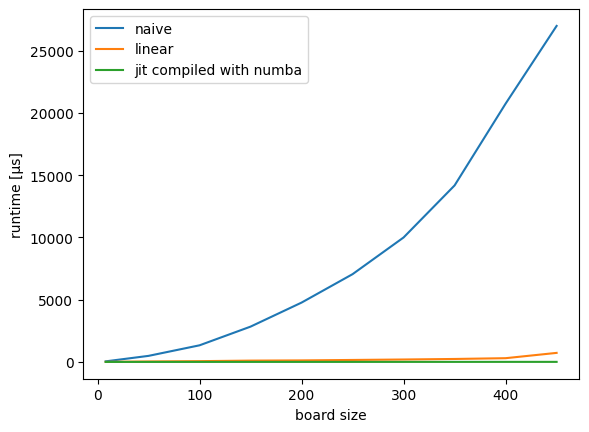

In [7]:
plt.plot(x, naive_times)
plt.plot(x, linear_times)
plt.plot(x, jit_times)
plt.xlabel("board size")
plt.ylabel("runtime [µs]")
plt.legend(["naive", "linear", "jit compiled with numba"])
plt.show()

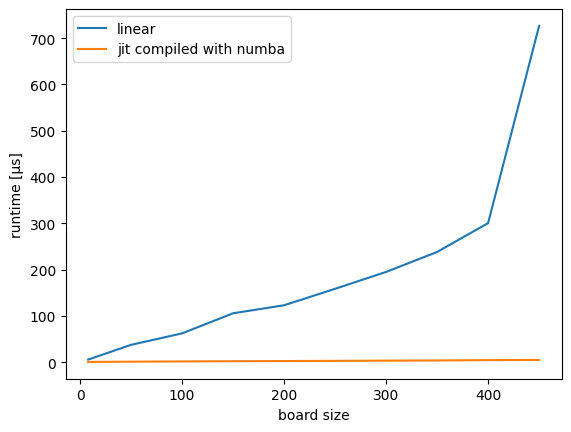

In [8]:
plt.plot(x, linear_times)
plt.plot(x, jit_times)
plt.xlabel("board size")
plt.ylabel("runtime [µs]")
plt.legend(["linear", "jit compiled with numba"])
plt.show()

---
# BÀI 6. TỐI ƯU HÀM ĐẾM XUNG ĐỘT BẰNG NUMBA

**Mục tiêu:** so sánh ba cách cài đặt `conflicts_naive()`, `conflicts()` và `conflicts_jit()` của notebook gốc; kiểm tra kết quả bằng nhau; đo thời gian trên nhiều kích thước n-Queens; giải thích độ phức tạp và lợi ích của biên dịch just-in-time (JIT). Phần mã bổ sung nằm dưới 14 cell gốc; trong phần gốc chỉ sửa nhãn trục thời gian từ `ms` thành `µs` vì các kết quả đã nhân với `1e6`.

**Mô hình n-Queens.** Bàn cờ là vector `board` gồm `n` số nguyên, với `board[col]` chỉ hàng chứa quân hậu tại cột `col`. Mỗi cột có đúng một quân hậu nên không có xung đột theo cột. Hai hậu xung đột nếu cùng hàng hoặc cùng một đường chéo. Giá trị mục tiêu `f(board)` bằng số *cặp* hậu tấn công nhau, cần tối thiểu hóa và bằng 0 tại một lời giải hợp lệ.

## 6.1. Công thức đếm theo hàng và hai đường chéo

Nếu một hàng hoặc một đường chéo có `k` quân hậu thì số cặp xung đột trên đường đó là:

$$C(k,2)=\frac{k(k-1)}{2}.$$

Với hậu ở cột `i`, hàng `q[i]`, ba chỉ số nhóm được sử dụng trong notebook là:

- Hàng: `q[i]` (có `n` nhóm).
- Đường chéo thứ nhất: `i + q[i]` (giá trị từ 0 đến `2n-2`).
- Đường chéo thứ hai: `i - q[i] + n` (giá trị từ 1 đến `2n-1`).

Sau khi đếm mỗi quân hậu đúng một lần vào từng nhóm, tổng `C(k,2)` trên các hàng và hai họ đường chéo chính là `conflicts(board)`. Một cặp hậu ở hai cột khác nhau chỉ có thể cùng hàng **hoặc** cùng một trong hai hướng đường chéo (không bị đếm hai lần).

`conflicts_naive()` sử dụng các phép quét lặp và vòng lặp lồng nhau, có thời gian O(n²). `conflicts()` và `conflicts_jit()` xây dựng bộ đếm kích thước O(n) rồi cộng các tổ hợp, nên có thời gian O(n) và bộ nhớ phụ O(n). Numba tăng tốc bằng cách biên dịch các vòng lặp, nhưng **không làm đổi bậc độ phức tạp O(n)** của thuật toán đếm tối ưu.

In [9]:
# Minh họa cách xây dựng bộ đếm xung đột theo cùng mô hình của notebook gốc.
def conflict_breakdown(board):
    board = np.asarray(board, dtype=np.int64)
    n = len(board)
    rows = np.bincount(board, minlength=n)
    diag_sum = np.bincount(np.arange(n) + board, minlength=2*n)
    diag_diff = np.bincount(np.arange(n) - board + n, minlength=2*n)
    pairs = lambda counts: int(sum(int(k) * (int(k)-1) // 2 for k in counts))
    return {'hang': pairs(rows), 'cheo_i_cong_hang': pairs(diag_sum),
            'cheo_i_tru_hang': pairs(diag_diff),
            'tong': pairs(rows) + pairs(diag_sum) + pairs(diag_diff)}

for q in ([1, 3, 0, 2], [0, 0, 0, 0], [0, 1, 2, 3]):
    detail = conflict_breakdown(q)
    print(f'board={q} | {detail} | naive={conflicts_naive(q)}')
    assert detail['tong'] == conflicts_naive(q) == conflicts(q)

board=[1, 3, 0, 2] | {'hang': 0, 'cheo_i_cong_hang': 0, 'cheo_i_tru_hang': 0, 'tong': 0} | naive=0
board=[0, 0, 0, 0] | {'hang': 6, 'cheo_i_cong_hang': 0, 'cheo_i_tru_hang': 0, 'tong': 6} | naive=6
board=[0, 1, 2, 3] | {'hang': 0, 'cheo_i_cong_hang': 0, 'cheo_i_tru_hang': 6, 'tong': 6} | naive=6


## 6.2. Kiểm thử tính đúng đắn của ba hàm

Để tránh việc so sánh thời gian giữa các hàm tính ra **kết quả khác nhau**, chương trình đối chiếu `conflicts_naive()`, `conflicts()` và `conflicts_jit()` trên các bàn cờ có nghiệm đã biết, bàn cờ có nhiều xung đột và các mẫu ngẫu nhiên từ `n=1` đến `n=512`. Sử dụng một hàm tham chiếu độc lập duyệt từng cặp hậu để kiểm tra thêm ở các kích thước nhỏ.

In [10]:
from pathlib import Path
import csv

RESULT_DIR_BAI6 = Path('Lab03_Bai6_Results')
IMAGE_DIR_BAI6 = RESULT_DIR_BAI6 / 'Images'
RESULT_DIR_BAI6.mkdir(exist_ok=True, parents=True)
IMAGE_DIR_BAI6.mkdir(exist_ok=True, parents=True)

# Hàm tham chiếu độc lập: kiểm tra đúng từng cặp quân hậu.
def conflicts_pairwise_reference(board):
    board = np.asarray(board)
    n = len(board)
    return sum(int(board[i] == board[j] or abs(int(board[i])-int(board[j])) == j-i)
               for i in range(n) for j in range(i+1, n))

rng_check = np.random.default_rng(20261015)
check_rows = []
test_boards = [np.asarray([1, 3, 0, 2], dtype=np.int64),
               np.asarray([3, 0, 2, 1], dtype=np.int64),
               np.asarray([0, 0, 0, 0], dtype=np.int64)]
for n in [1, 2, 4, 8, 16, 32, 64, 128, 256, 512]:
    test_boards += [rng_check.integers(0, n, size=n, dtype=np.int64) for _ in range(5)]
for idx, board in enumerate(test_boards):
    ans = [int(fun(board)) for fun in (conflicts_naive, conflicts, conflicts_jit)]
    assert ans[0] == ans[1] == ans[2], (idx, len(board), ans)
    if len(board) <= 32:
        assert ans[0] == conflicts_pairwise_reference(board)
    check_rows.append({'case': idx, 'n': len(board), 'naive': ans[0],
                       'linear': ans[1], 'jit': ans[2], 'equal': True})
assert int(conflicts(np.array([1, 3, 0, 2]))) == 0
with (RESULT_DIR_BAI6 / 'Bai6_Correctness_Checks.csv').open('w', newline='', encoding='utf-8-sig') as f:
    writer = csv.DictWriter(f, fieldnames=check_rows[0].keys())
    writer.writeheader(); writer.writerows(check_rows)
print(f'PASS: {len(check_rows)} bàn cờ đều cho kết quả trùng nhau ở ba hàm.')
print('Nghiệm [1,3,0,2] có f=0; kiểm tra tham chiếu độc lập cũng thành công.')

PASS: 53 bàn cờ đều cho kết quả trùng nhau ở ba hàm.
Nghiệm [1,3,0,2] có f=0; kiểm tra tham chiếu độc lập cũng thành công.


## 6.3. Phân biệt thời gian biên dịch JIT và thời gian thực thi

`@njit` biên dịch một phiên bản chuyên biệt theo kiểu dữ liệu của các đối số khi hàm được gọi lần đầu. Vì vậy, lần gọi đầu tiên có thể chậm do bao gồm cả thời gian biên dịch. Trước mọi phép đo tốc độ phía dưới, cần **gọi thử `conflicts_jit()` trước**, với cùng kiểu mảng `np.int64` được dùng cho benchmark.

Đoạn thử nghiệm sau cố ý dùng `np.int32` để yêu cầu một chữ ký mới, nhờ đó có thể minh họa chi phí biên dịch lần đầu mà không làm ảnh hưởng đến chữ ký `np.int64` đã làm nóng. Đây là phép minh họa cơ chế JIT, **không đưa số liệu biên dịch vào bảng thời gian thuật toán chính**.

In [11]:
import time
jit_probe32 = np.asarray([1, 3, 0, 2], dtype=np.int32)
# Sau khi notebook gốc đã chạy, chữ ký int64 đã được biên dịch.
int64_probe = np.asarray([1, 3, 0, 2], dtype=np.int64)
assert int(conflicts_jit(int64_probe)) == 0

first_start = time.perf_counter_ns()
first_result = int(conflicts_jit(jit_probe32))
first_us = (time.perf_counter_ns() - first_start) / 1000
warm_us = []
for _ in range(200):
    t0 = time.perf_counter_ns()
    assert int(conflicts_jit(jit_probe32)) == first_result
    warm_us.append((time.perf_counter_ns() - t0) / 1000)
print(f'JIT chữ ký int32 mới - lần đầu: {first_us:,.1f} µs')
print(f'JIT cùng chữ ký int32 - trung vị 200 lượt tiếp: {np.median(warm_us):,.3f} µs')
print('Các chữ ký đã biên dịch:', conflicts_jit.signatures)
with (RESULT_DIR_BAI6 / 'Bai6_JIT_Compile_Demo.csv').open('w', newline='', encoding='utf-8-sig') as f:
    wr=csv.writer(f); wr.writerow(['signature', 'first_call_us', 'warm_median_us'])
    wr.writerow(['int32[:]', round(first_us,4), round(float(np.median(warm_us)),4)])

JIT chữ ký int32 mới - lần đầu: 171,360.1 µs
JIT cùng chữ ký int32 - trung vị 200 lượt tiếp: 0.380 µs
Các chữ ký đã biên dịch: [(Array(int64, 1, 'C', False, aligned=True),), (Array(int32, 1, 'C', False, aligned=True),)]


## 6.4. Đo thời gian trên nhiều kích thước bàn cờ

Chạy cùng ba hàm trên cùng các bàn cờ sinh từ bộ tạo số ngẫu nhiên có seed cố định. Mỗi kích thước dùng `20` bàn cờ, mỗi bộ phép đo được lặp `5` lần; thời gian báo cáo là **trung vị thời gian trên mỗi bàn cờ, đơn vị micro giây (µs)**. Numba đã được làm nóng trước khi đo. Dùng `timeit.repeat` để hạn chế ảnh hưởng của các dao động thời gian ngẫu nhiên; kết quả vẫn phụ thuộc vào máy tính và môi trường thực thi.

Thứ tự kích thước tăng theo cấp số nhân nhằm quan sát rõ tính mở rộng. Việc gọi hàm qua Python, tạo danh sách kết quả và bộ nhớ đệm có thể ảnh hưởng đáng kể ở n nhỏ; do vậy không nên suy bậc độ phức tạp chỉ từ một vài số đo nhỏ.

In [12]:
import timeit
import statistics

rng_bench = np.random.default_rng(20261016)
board_sizes = [4, 8, 16, 32, 64, 128, 256, 512]
boards_per_size = 20
measurement_repeats = 5
functions_bai6 = [('Naive O(n²)', conflicts_naive),
                  ('Linear O(n)', conflicts),
                  ('Numba JIT O(n)', conflicts_jit)]
# Warm-up đúng chữ ký đã dùng bởi benchmark.
assert int(conflicts_jit(np.asarray([1, 3, 0, 2], dtype=np.int64))) == 0
benchmark_rows = []
raw_rows = []
for n in board_sizes:
    boards = [rng_bench.integers(0, n, size=n, dtype=np.int64)
              for _ in range(boards_per_size)]
    baseline = [int(conflicts(board)) for board in boards]
    times = {}
    for label, func in functions_bai6:
        assert [int(func(board)) for board in boards] == baseline
        batches = timeit.repeat(lambda: [func(board) for board in boards],
                                repeat=measurement_repeats, number=1)
        microseconds = [elapsed * 1e6 / boards_per_size for elapsed in batches]
        times[label] = float(statistics.median(microseconds))
        for rep, value in enumerate(microseconds, start=1):
            raw_rows.append({'n': n, 'algorithm': label, 'repeat': rep,
                             'microseconds_per_board': value})
    benchmark_rows.append({'n': n,
                           'naive_us': times['Naive O(n²)'],
                           'linear_us': times['Linear O(n)'],
                           'jit_us': times['Numba JIT O(n)'],
                           'speedup_linear_vs_naive': times['Naive O(n²)']/times['Linear O(n)'],
                           'speedup_jit_vs_naive': times['Naive O(n²)']/times['Numba JIT O(n)'],
                           'speedup_jit_vs_linear': times['Linear O(n)']/times['Numba JIT O(n)']})
with (RESULT_DIR_BAI6 / 'Bai6_Benchmark_Summary.csv').open('w', newline='', encoding='utf-8-sig') as f:
    wr=csv.DictWriter(f, fieldnames=list(benchmark_rows[0]));wr.writeheader();wr.writerows(benchmark_rows)
with (RESULT_DIR_BAI6 / 'Bai6_Benchmark_Raw.csv').open('w', newline='', encoding='utf-8-sig') as f:
    wr=csv.DictWriter(f, fieldnames=list(raw_rows[0]));wr.writeheader();wr.writerows(raw_rows)
print('n     naive (µs)   linear (µs)    jit (µs)  JIT vs naive')
for r in benchmark_rows:
    print(f"{r['n']:>3d} {r['naive_us']:>13.2f} {r['linear_us']:>13.2f}"
          f" {r['jit_us']:>11.2f} {r['speedup_jit_vs_naive']:>11.1f}x")

n     naive (µs)   linear (µs)    jit (µs)  JIT vs naive
  4         15.23          3.08        0.25        60.2x
  8         29.84          4.98        0.29       103.5x
 16         88.84          9.65        0.35       256.8x
 32        215.78         18.76        0.51       422.5x
 64        603.06         37.56        0.75       801.8x
128       2131.81         80.43        1.28      1662.4x
256       7855.40        156.05        2.39      3281.2x
512      29777.27        311.91        4.49      6632.3x


## 6.5. Trực quan hóa kết quả

Đồ thị thứ nhất sử dụng thang log-log ở cả hai trục để so sánh xu hướng tăng thời gian khi n lớn dần. Đồ thị thứ hai biểu diễn tỷ lệ tăng tốc khi chuyển từ cách đếm naive sang cách đếm tuyến tính hoặc Numba. Cả hai được tạo từ chính bảng CSV thực nghiệm phía trên; trục thời gian dùng micro giây (µs), không phải mili giây.

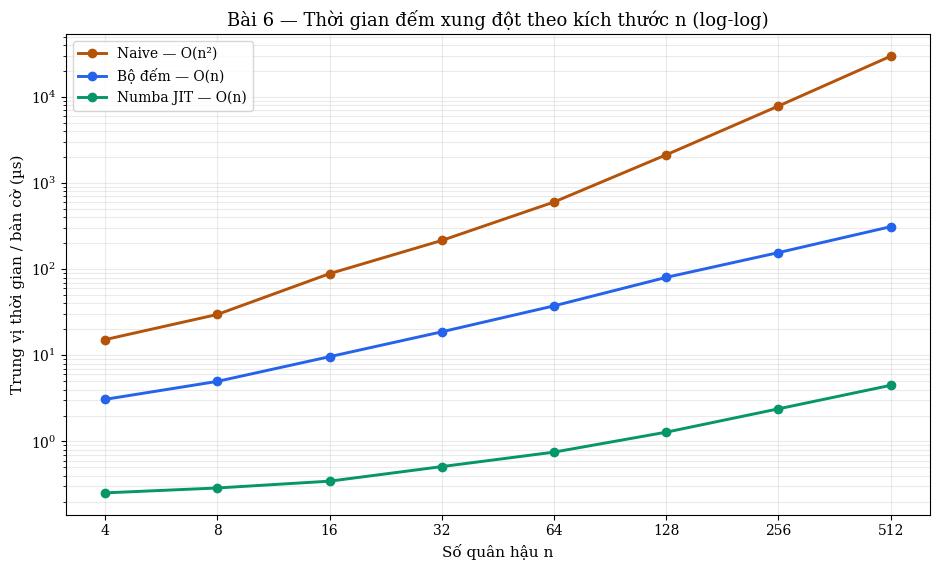

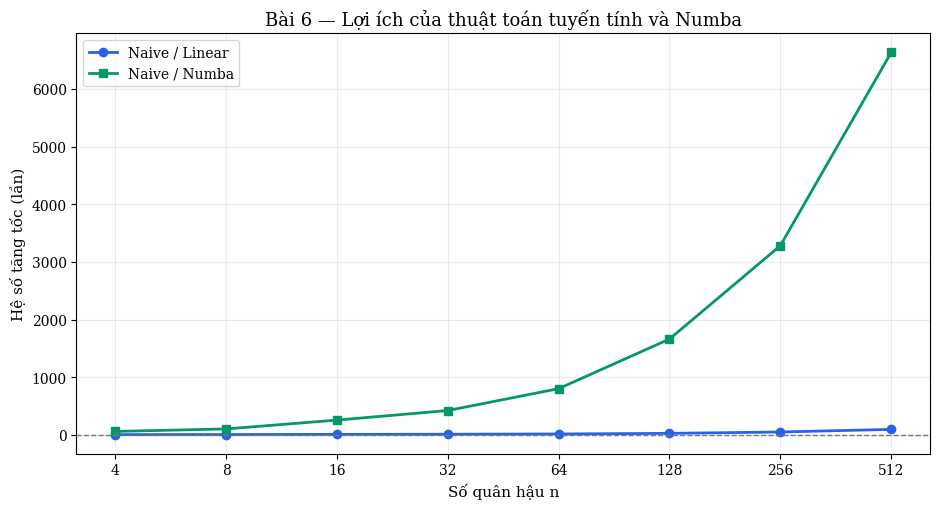

In [13]:
import matplotlib.pyplot as plt
plt.rcParams.update({'font.family': 'DejaVu Serif', 'axes.titlesize': 13, 'axes.labelsize': 11})
size_array = np.array([row['n'] for row in benchmark_rows])
fig, ax = plt.subplots(figsize=(9.5, 5.8))
for key, label, color in [
    ('naive_us', 'Naive — O(n²)', '#b45309'),
    ('linear_us', 'Bộ đếm — O(n)', '#2563eb'),
    ('jit_us', 'Numba JIT — O(n)', '#059669')]:
    ax.plot(size_array, [row[key] for row in benchmark_rows],
            marker='o', lw=2.1, label=label, color=color)
ax.set_xscale('log', base=2);ax.set_yscale('log')
ax.set_xticks(size_array);ax.set_xticklabels([str(k) for k in size_array])
ax.set_xlabel('Số quân hậu n'); ax.set_ylabel('Trung vị thời gian / bàn cờ (µs)')
ax.set_title('Bài 6 — Thời gian đếm xung đột theo kích thước n (log-log)')
ax.grid(True, which='both', alpha=.25);ax.legend()
fig.tight_layout()
fig.savefig(IMAGE_DIR_BAI6 / 'Bai6_Runtime_LogLog.png', dpi=180, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(9.5, 5.2))
ax.plot(size_array, [row['speedup_linear_vs_naive'] for row in benchmark_rows],
        'o-', lw=2, label='Naive / Linear', color='#2563eb')
ax.plot(size_array, [row['speedup_jit_vs_naive'] for row in benchmark_rows],
        's-', lw=2, label='Naive / Numba', color='#059669')
ax.axhline(1, linestyle='--', lw=1, color='#777777')
ax.set_xscale('log',base=2);ax.set_xticks(size_array)
ax.set_xticklabels([str(k) for k in size_array])
ax.set_xlabel('Số quân hậu n');ax.set_ylabel('Hệ số tăng tốc (lần)')
ax.set_title('Bài 6 — Lợi ích của thuật toán tuyến tính và Numba')
ax.grid(True, alpha=.25);ax.legend();fig.tight_layout()
fig.savefig(IMAGE_DIR_BAI6 / 'Bai6_Speedup_Comparison.png', dpi=180, bbox_inches='tight')
plt.show()

## 6.6. Nhận xét và kết luận

- Cả ba hàm tính cùng một hàm mục tiêu: tổng số cặp hậu xung đột theo hàng và hai hướng đường chéo. Các phép kiểm thử thực nghiệm xác nhận ba kết quả bằng nhau trên những bàn cờ khảo sát, bao gồm nghiệm mẫu `[1,3,0,2]` với `f=0`.
- `conflicts_naive()` có bậc thời gian O(n²) vì cần duyệt các quân hậu theo cặp (và thực hiện nhiều phép đếm theo hàng). `conflicts()` dùng ba bộ đếm có tổng chiều dài tỉ lệ với n, tính `C(k,2)` nên chỉ cần O(n) thời gian và O(n) bộ nhớ bổ sung.
- `conflicts_jit()` giữ nguyên nguyên lý đếm O(n), nhưng sử dụng biên dịch JIT của Numba để giảm overhead chạy các vòng lặp Python. Tăng tốc do JIT là tối ưu **cài đặt**, khác với giảm độ phức tạp từ O(n²) xuống O(n) là tối ưu **thuật toán**.
- Thời gian của lần gọi JIT đầu tiên có thể lớn do phải biên dịch; so sánh công bằng cần gọi `conflicts_jit()` trước benchmark và đo trên cùng kiểu dữ liệu. Giá trị trung vị của nhiều lượt đo đáng tin cậy hơn một lần duy nhất, tuy không loại bỏ hoàn toàn dao động hệ thống.
- Đồ thị log-log giúp quan sát khi n tăng thì thời gian naive có xu hướng tăng nhanh hơn hai phiên bản tuyến tính. Tỷ lệ tăng tốc thực tế phụ thuộc môi trường, kích thước n, overhead gọi hàm và bộ nhớ đệm, không phải một hằng số phổ quát.

**Kết luận:** Phối hợp bộ đếm theo hàng/đường chéo với công thức tổ hợp làm giảm số phép toán tiệm cận từ O(n²) xuống O(n). Biên dịch JIT tiếp tục tối ưu tốc độ thực thi mà không thay đổi độ phức tạp của thuật toán. Trong những thuật toán tìm kiếm cục bộ phải tính `conflicts(board)` lặp lại rất nhiều lần, việc tối ưu hàm mục tiêu có thể giảm đáng kể tổng thời gian chạy.